## wd

In [1]:
### Mounting Google Drive :
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pwd

/content


In [3]:
working_dir = "/content/drive/MyDrive/Analisis de datos"
%cd $working_dir

/content/drive/MyDrive/Analisis de datos


In [4]:
!pwd

/content/drive/MyDrive/Analisis de datos


In [5]:
import pandas as pd
import numpy as np

# Modelos No Supervisados - Métodos para datos Mixtos

La clave es que Gower proporciona la distancia para datos mixtos; de manera que el algoritmo de clustering seleccionado deba poder trabajar con la matriz de distancia de estos datos mixtos.

Datos mixtos: que el dataset contiene variables numericas y categoricas al mismo tiempo

In [6]:
!pip install gower
!pip install kmodes scikit-learn-extra hdbscan

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 9.2 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp313-cp313-linux_x86_64.whl size=2154556 sha256=cc4257ad7492fec77ff619ca9b3b494e5fba137d2dcd64781508561501aa71d8
  Stored in directory: /root/.cache/pip/wheels/17/4b/b8/6b6711681d0981b110c9cc91ad6d1ebd88adf1547e1da301fc
Successfully built scikit-learn-extra
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [kmodes]


In [7]:
x_scaled2 = pd.read_csv("x_scaled2_bin.csv")
x_scaled2.head(5)

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,bin_SINEQUIPOSDECOMUNICACION
0,0.165466,0.210741,0.075867,0.181503,0.017276,0.089122,0.099573,0.4,"(0.0999, 0.117]"
1,0.020000,0.220000,0.150000,0.045802,0.446565,0.184000,0.251908,0.2,"(0.134, 0.151]"
2,0.546547,0.696697,0.276276,0.182218,0.688380,0.178236,0.090669,0.4,"(0.134, 0.151]"
3,0.127358,0.169811,0.122642,0.110592,0.300623,0.099673,0.182243,0.4,"(0.134, 0.151]"
4,0.784314,0.852941,0.343137,0.052991,0.678632,0.186715,0.073504,0.4,"(0.151, 0.168]"


In [8]:
cat_cols = list(x_scaled2.select_dtypes(['object', 'string', 'category']).columns)
num_cols = list(x_scaled2.select_dtypes(['float64', 'int64']).columns)

In [9]:
X = x_scaled2[num_cols + cat_cols].copy()

for col in cat_cols:
    X[col] = X[col].astype(str) # convierte las variables categoricas a texto

In [10]:
import gower

D = gower.gower_matrix(X)
D

array([[0.        , 0.29152524, 0.33709052, ..., 0.33707294, 0.30660707,
        0.50821966],
       [0.29152524, 0.        , 0.23916495, ..., 0.3703087 , 0.26099664,
        0.48558563],
       [0.33709052, 0.23916495, 0.        , ..., 0.20798694, 0.14626116,
        0.30931842],
       ...,
       [0.33707294, 0.3703087 , 0.20798694, ..., 0.        , 0.19863498,
        0.3092307 ],
       [0.30660707, 0.26099664, 0.14626116, ..., 0.19863498, 0.        ,
        0.38429973],
       [0.50821966, 0.48558563, 0.30931842, ..., 0.3092307 , 0.38429973,
        0.        ]], dtype=float32)

In [11]:
print(type(D))
print(D.shape)

<class 'numpy.ndarray'>
(1847, 1847)


# a) K-Prototypes

Revisar notebook anterior

Tener en cuenta que K-Prototypes no utiliza directamente D. Necesita la matriz original de variables mixtas.

# b) Gower + Jerárquico

In [12]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

D_condensed = squareform(D, checks=False) # forma de poner los datos , es False porque se dice que no comprueba si la matriz
# es simetrica y tiene ceros en la diagonal
D_condensed

array([0.29152524, 0.33709052, 0.19088893, ..., 0.19863498, 0.3092307 ,
       0.38429973], dtype=float32)

In [13]:
Z = linkage(D_condensed, method="average")
# average: calcula el promedio de todas las distancias entre sus integrantes.
Z # historial de las uniones que realizó el algoritmo jerárquico.

array([[1.28200000e+03, 1.30700000e+03, 4.13633930e-03, 2.00000000e+00],
       [1.27600000e+03, 1.27800000e+03, 4.41424642e-03, 2.00000000e+00],
       [3.35000000e+02, 1.30300000e+03, 4.69521945e-03, 2.00000000e+00],
       ...,
       [3.68800000e+03, 3.68900000e+03, 3.28968795e-01, 1.28500000e+03],
       [3.68700000e+03, 3.69000000e+03, 3.38718276e-01, 1.84600000e+03],
       [1.02500000e+03, 3.69100000e+03, 3.56779748e-01, 1.84700000e+03]])

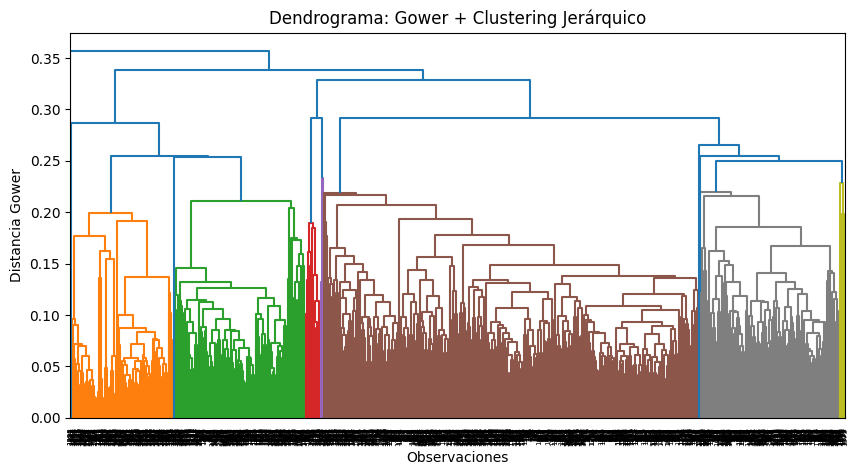

In [14]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram

plt.figure(figsize=(10, 5))
dendrogram(Z)
plt.title("Dendrograma: Gower + Clustering Jerárquico")
plt.xlabel("Observaciones")
plt.ylabel("Distancia Gower")
plt.show()

* D → matriz cuadrada de distancias n × n.

* D_condensed → vector de distancias en formato condensado.

Ej de D_condensada: [0.2, 0.7, 0.5, 0.6, 0.4, 0.3]

Se interpreta como:
A-B = 0.2
A-C = 0.7
A-D = 0.5
B-C = 0.6
B-D = 0.4
C-D = 0.3

* Z → matriz de linkage generada a partir de las distancias.

Ej de Z, con method "average":
[[0.   1.   0.2  2. ]
 [2.   3.   0.3  2. ]
 [4.   5.   0.55 4. ]]


In [15]:
# Número de clusters seleccionado
k = 4

clusters_hier = fcluster(Z, t=k, criterion="maxclust")
# Le pedimos que encuentre un corte de la jerarquía que produzca como máximo esa cantidad de grupos.

print(np.unique(clusters_hier, return_counts=True))


(array([1, 2, 3, 4], dtype=int32), array([ 561,   43, 1242,    1]))


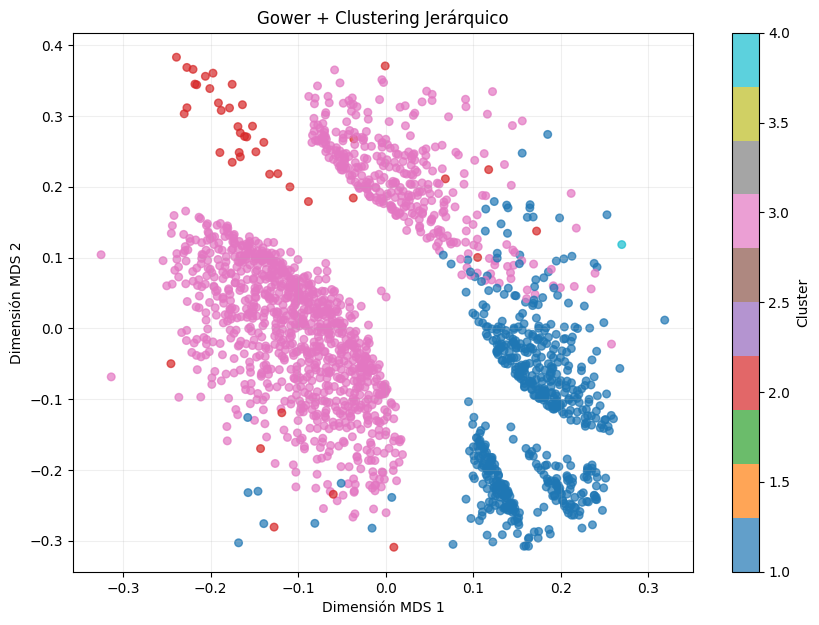

In [16]:
# GRÁFICO - GOWER + JERÁRQUICO

import matplotlib.pyplot as plt
from sklearn.manifold import MDS

D_float = np.asarray(D, dtype=np.float64) # se convierte la matriz de distancias

mds = MDS(
    n_components=2, # en el numero de dimensiones
    dissimilarity="precomputed", # Las distancias ya fueron calculadas con Gower.
    random_state=42
) # intenta colocar las distancias en un grafico de 2 dimensiones

coords = mds.fit_transform(D_float) # calcula dos coordenadas para cada distrito

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    coords[:, 0], # coordenadas x
    coords[:, 1], # coordenadas y
    c=clusters_hier,
    cmap="tab10",
    s=30,
    alpha=0.7
)

plt.colorbar(scatter, label="Cluster")
plt.title("Gower + Clustering Jerárquico")
plt.xlabel("Dimensión MDS 1")
plt.ylabel("Dimensión MDS 2")
plt.grid(alpha=0.2)

plt.show()


De todas las variables que tengo y con las distancias que saqué de Gower, si lo pongo en 2 dimensiones, ¿así quedan los clusters? ¡Sí! Pero es una representación aproximada, no exacta.

Tener en cuenta que:

Al reducir tanta información a solamente dos dimensiones, MDS puede crear separaciones visuales que no representan necesariamente clusters estadísticamente definidos.

Eso significa que, aunque visualmente parecen dos grupos, con el criterio de del modelo, no existe suficiente evidencia para considerarlos dos clusters dentro de los puntos de color rosado por ejemplo.

Interpretación: "La representación bidimensional mediante MDS muestra cierta estructura visual en los datos; sin embargo, el modelo (Jerárquico), utilizando las distancias Gower originales, no identificó dichas regiones lo suficientemente diferenciadas bajo los parámetros utilizados."

# c) Gower + PAM/K-Medoids

In [20]:
from sklearn_extra.cluster import KMedoids

k = 3

pam = KMedoids(
    n_clusters=k,
    metric="precomputed",
    random_state=42
)

clusters_pam = pam.fit_predict(D)

print(np.unique(clusters_pam, return_counts=True))


(array([0, 1, 2]), array([692, 591, 564]))


El meoide es una observacion real de la base que representa a un conglomerado.

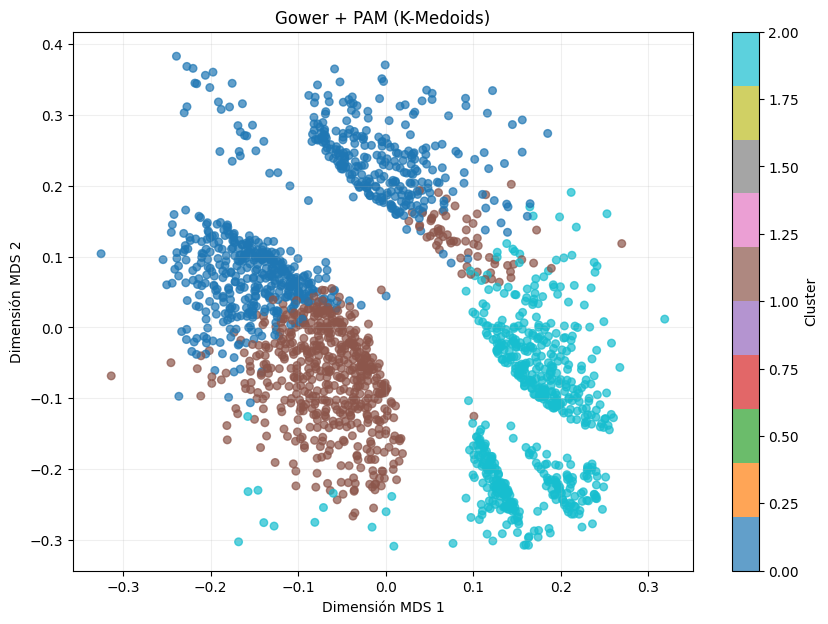

In [18]:
# GRÁFICO - GOWER + PAM

import matplotlib.pyplot as plt
from sklearn.manifold import MDS

D_float = np.asarray(D, dtype=np.float64)

mds = MDS(
    n_components=2,
    dissimilarity="precomputed",
    random_state=42
)

coords = mds.fit_transform(D_float)

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    coords[:, 0],
    coords[:, 1],
    c=clusters_pam,
    cmap="tab10",
    s=30,
    alpha=0.7
)

plt.colorbar(scatter, label="Cluster")
plt.title("Gower + PAM (K-Medoids)")
plt.xlabel("Dimensión MDS 1")
plt.ylabel("Dimensión MDS 2")
plt.grid(alpha=0.2)

plt.show()


el grupo azul presenta una concentración visible, pero no está completamente separado de los demás.
este conglomerado presenta un solapamiento visual considerable con los otros grupos, por lo que su separación no es tan clara en las dos dimensiones representadas.
el grupo celeste presenta una separación visual más marcada respecto a los otros dos, aunque también existen puntos celestes dispersos y zonas de mezcla.

# d) Gower + DBSCAN

En DBSCAN, la etiqueda de -1 significa cluster considerado outlier o ruido.

In [19]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.3, #  el radio, es ese valor porque Gower da distancias de 0 a 1
    min_samples=5, # va a buscar 5 dentro de su vencindad, contandose a si mismo
    metric="precomputed"
)

clusters_dbscan = dbscan.fit_predict(D)

print(np.unique(clusters_dbscan, return_counts=True))


(array([0]), array([1847]))


In [21]:
n_outliers = np.sum(clusters_dbscan == -1)

print("Número de outliers:", n_outliers)


Número de outliers: 0


## ¿Cómo elegir eps para DBSCAN?

Podemos mirar la distribución de distancias de cada observación a sus vecinos.

La idea es analizar que tan lejos esta cada distrito de su quinto vecino mas cercano

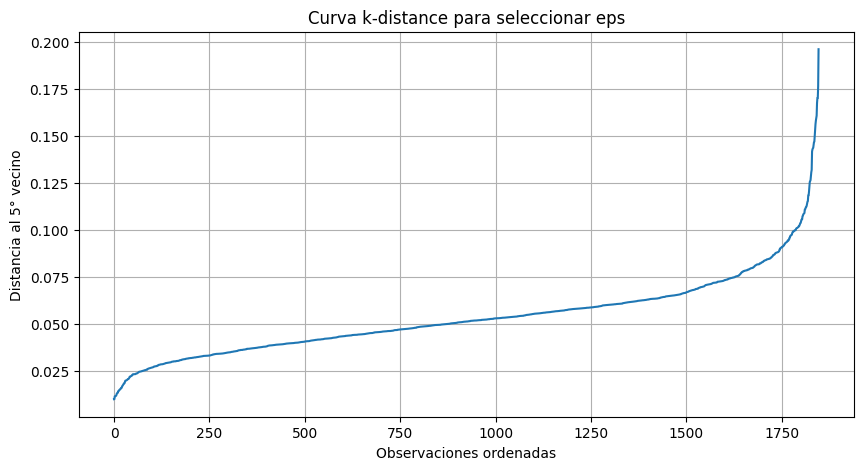

In [22]:
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt

k = 5 # numero de vecinos a analizar mismo que min_samples

neigh = NearestNeighbors(
    n_neighbors=k,
    metric="precomputed" # se utilizara las distancias que ya hicimos
)

neigh.fit(D) # se busca

distances, indices = neigh.kneighbors(D) # guarda distancias e indices de esos vecinos

k_distances = np.sort(distances[:, -1]) # quedarse con la ultima distancia de sus cinco vecinos, ordenar de menor a mayor

plt.figure(figsize=(10, 5))

plt.plot(k_distances)

plt.xlabel("Observaciones ordenadas")
plt.ylabel(f"Distancia al {k}° vecino")
plt.title("Curva k-distance para seleccionar eps")

plt.grid()
plt.show()


La curva sube lentamente, significa que muchos distritos tienen a su quitno vecino relativamente cerca, y a partir de 0.08 aprox sube muy rapido, eso significa que hay algunos distritos cuyo quinto vecino esta bastante mas lejos.  Se busca el punto de la curva donde deja de subir lentamente y comienza a elevarse rapidamente.

Si buscamos aproximadamente el "codo" de la curva, este valor puede servir como eps.

In [23]:
dbscan = DBSCAN(
    eps=0.097,
    min_samples=50,
    metric="precomputed"
)

clusters_dbscan = dbscan.fit_predict(D)


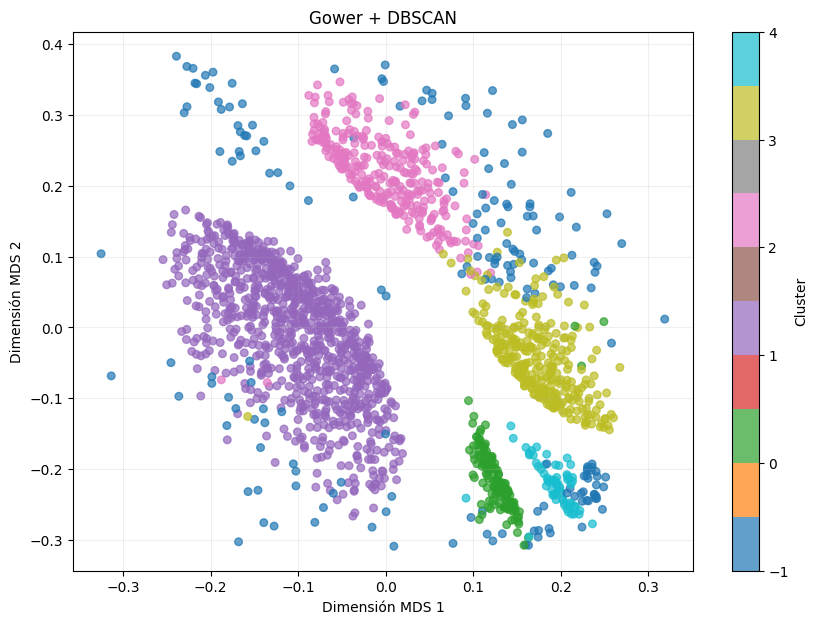

In [24]:
# GRÁFICO - GOWER + DBSCAN

import matplotlib.pyplot as plt
from sklearn.manifold import MDS

D_float = np.asarray(D, dtype=np.float64)

mds = MDS(
    n_components=2,
    dissimilarity="precomputed",
    random_state=42
)

coords = mds.fit_transform(D_float)

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    coords[:, 0],
    coords[:, 1],
    c=clusters_dbscan,
    cmap="tab10",
    s=30,
    alpha=0.7
)

plt.colorbar(scatter, label="Cluster")
plt.title("Gower + DBSCAN")
plt.xlabel("Dimensión MDS 1")
plt.ylabel("Dimensión MDS 2")
plt.grid(alpha=0.2)

plt.show()


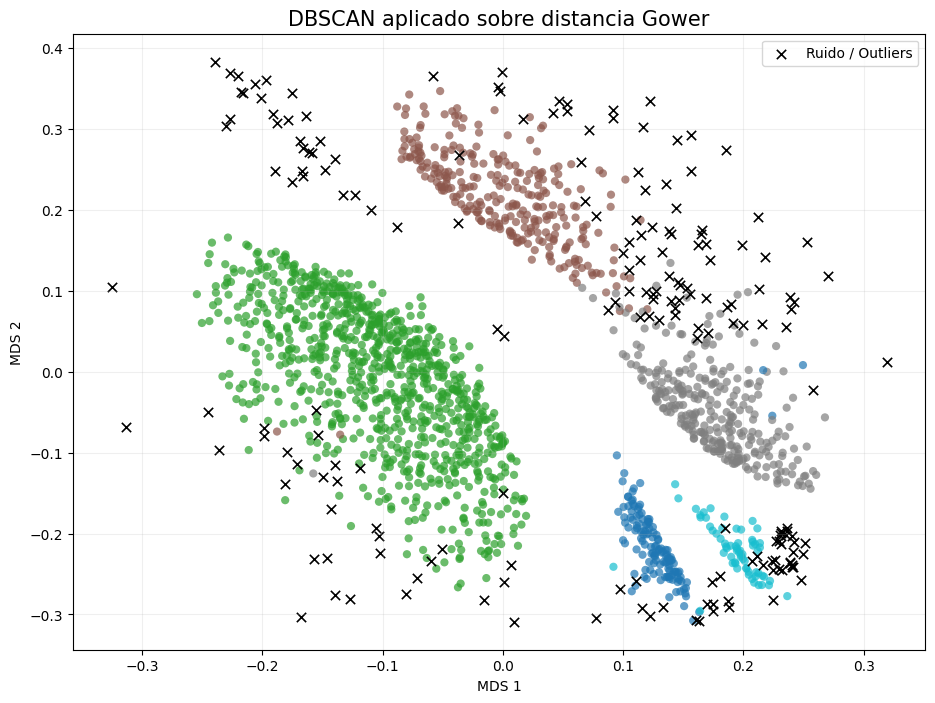

In [25]:
# GRÁFICO TÍPICO DE DBSCAN

import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import MDS

D_float = np.asarray(D, dtype=np.float64)

# Reducimos las distancias Gower a 2 dimensiones
mds = MDS(
    n_components=2,
    dissimilarity="precomputed",
    random_state=42
)

coords = mds.fit_transform(D_float)


# Separamos clusters y ruido
mask_outliers = clusters_dbscan == -1
mask_clusters = clusters_dbscan != -1

plt.figure(figsize=(11, 8))


# Clusters
plt.scatter(
    coords[mask_clusters, 0],
    coords[mask_clusters, 1],
    c=clusters_dbscan[mask_clusters],
    cmap="tab10",
    s=35,
    alpha=0.70,
    edgecolors="none"
)


# Outliers / ruido
plt.scatter(
    coords[mask_outliers, 0],
    coords[mask_outliers, 1],
    c="black",
    marker="x",
    s=45,
    linewidths=1.2,
    label="Ruido / Outliers"
)

plt.title("DBSCAN aplicado sobre distancia Gower", fontsize=15)
plt.xlabel("MDS 1")
plt.ylabel("MDS 2")

plt.grid(alpha=0.2)
plt.legend()

plt.show()


# e) Gower + HDBSCAN

HDBSCAN es muy interesante porque puede encontrar clusters con diferentes densidades.

HDBSCAN analiza la estructura de densidades a diferentes escalas, en lugar de depender de un único radio eps. Así puede identificar grupos más compactos y otros menos compactos, siempre que tengan suficiente estabilidad y estructura.

In [27]:
import hdbscan

D = np.asarray(D, dtype=np.float64)

clusterer = hdbscan.HDBSCAN(
    min_cluster_size=50, # estamos estableciendo 50 observaciones como tamaño mínimo deseado para un cluster.
    metric="precomputed"
)

clusters_hdbscan = clusterer.fit_predict(D)

print(np.unique(clusters_hdbscan, return_counts=True))


(array([-1,  0,  1,  2,  3,  4]), array([264, 261, 859, 271, 131,  61]))


In [28]:
n_outliers_hdbscan = np.sum(clusters_hdbscan == -1)

print("Outliers:", n_outliers_hdbscan)


Outliers: 264


In [29]:
clusters_validos = set(clusters_hdbscan)

clusters_validos.discard(-1)

print("Número de clusters:", len(clusters_validos))


Número de clusters: 5


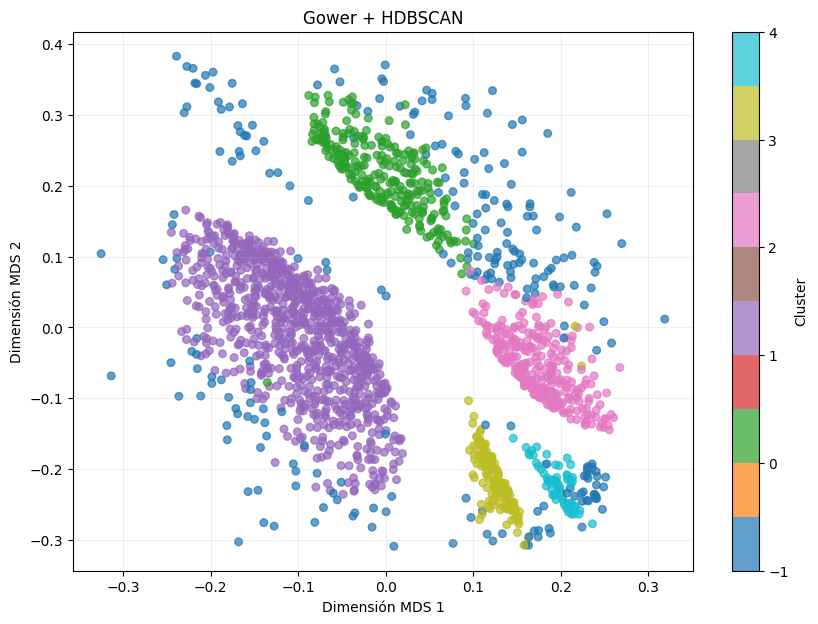

In [30]:
# ============================================================
# GRÁFICO - GOWER + HDBSCAN
# ============================================================

import matplotlib.pyplot as plt
from sklearn.manifold import MDS

D_float = np.asarray(D, dtype=np.float64)

mds = MDS(
    n_components=2,
    dissimilarity="precomputed",
    random_state=42
)

coords = mds.fit_transform(D_float)

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    coords[:, 0],
    coords[:, 1],
    c=clusters_hdbscan,
    cmap="tab10",
    s=30,
    alpha=0.7
)

plt.colorbar(scatter, label="Cluster")
plt.title("Gower + HDBSCAN")
plt.xlabel("Dimensión MDS 1")
plt.ylabel("Dimensión MDS 2")
plt.grid(alpha=0.2)

plt.show()


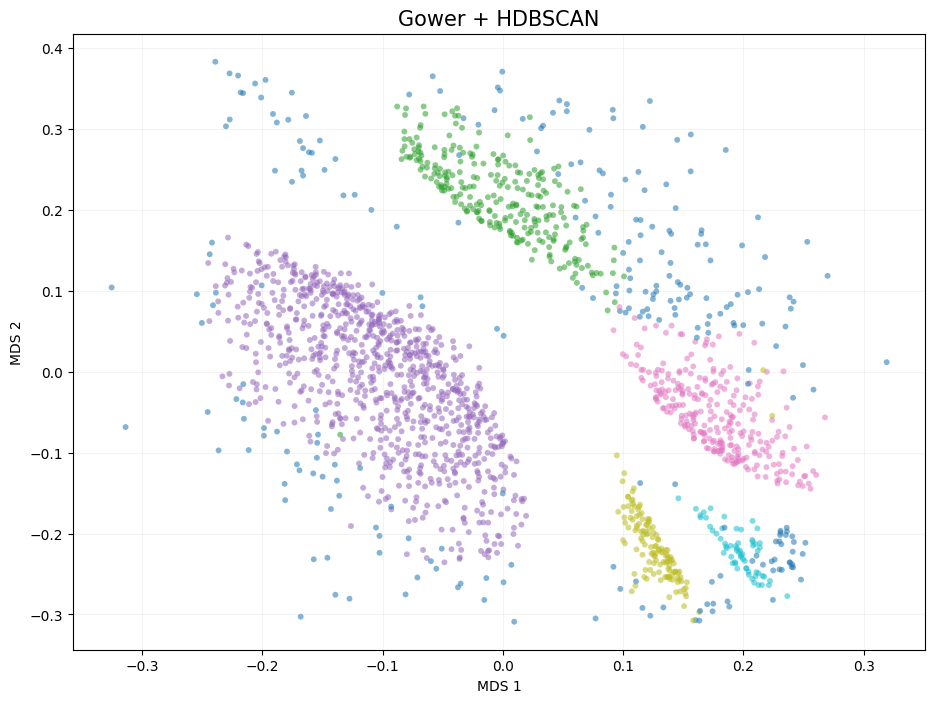

In [31]:
plt.figure(figsize=(11, 8))

plt.scatter(
    coords[:, 0],
    coords[:, 1],
    c=clusters_hdbscan,
    cmap="tab10",
    s=18,
    alpha=0.55,
    edgecolors="none"
)

plt.title("Gower + HDBSCAN", fontsize=15)
plt.xlabel("MDS 1")
plt.ylabel("MDS 2")
plt.grid(alpha=0.15)

plt.show()


# Comparando los resultados

In [32]:
resultados = pd.DataFrame(index=x_scaled2.index)

resultados["Jerarquico"] = clusters_hier
resultados["PAM"] = clusters_pam
resultados["DBSCAN"] = clusters_dbscan
resultados["HDBSCAN"] = clusters_hdbscan
#resultados["KPrototypes"] = clusters_kproto

resultados.head()


,Jerarquico,PAM,DBSCAN,HDBSCAN
0,1,2,0,3
1,3,1,1,1
2,3,1,1,1
3,3,1,1,1
4,3,0,2,0


In [33]:
for metodo in resultados.columns:

    print("----------------------")
    print(metodo)
    print("----------------------")

    print(resultados[metodo].value_counts().sort_index())


----------------------
Jerarquico
----------------------
Jerarquico
1     561
2      43
3    1242
4       1
Name: count, dtype: int64
----------------------
PAM
----------------------
PAM
0    692
1    591
2    564
Name: count, dtype: int64
----------------------
DBSCAN
----------------------
DBSCAN
-1    192
 0    133
 1    885
 2    283
 3    290
 4     64
Name: count, dtype: int64
----------------------
HDBSCAN
----------------------
HDBSCAN
-1    264
 0    261
 1    859
 2    271
 3    131
 4     61
Name: count, dtype: int64


# Evaluación de los clusters con Silhouette

In [34]:
from sklearn.metrics import silhouette_score

def evaluar_silhouette(D, labels, nombre):

    # Eliminamos outliers (-1)
    mask = labels != -1

    labels_validos = labels[mask]

    if len(np.unique(labels_validos)) < 2:
        print(nombre, ": no se puede calcular")
        return np.nan

    score = silhouette_score(
        D[np.ix_(mask, mask)],
        labels_validos,
        metric="precomputed"
    )

    print(nombre, ":", round(score, 4))

    return score


In [35]:
sil_hier = evaluar_silhouette(
    D,
    clusters_hier,
    "Jerárquico"
)

sil_pam = evaluar_silhouette(
    D,
    clusters_pam,
    "PAM"
)

sil_dbscan = evaluar_silhouette(
    D,
    clusters_dbscan,
    "DBSCAN"
)


sil_hdbscan = evaluar_silhouette(
    D,
    clusters_hdbscan,
    "HDBSCAN"
)


Jerárquico : 0.2688
PAM : 0.2449
DBSCAN : 0.4155
HDBSCAN : 0.424


In [36]:
comparacion = pd.DataFrame({
    "Método": [
        "Jerárquico",
        "PAM",
        "DBSCAN",
        "HDBSCAN"
    ],
    "Silhouette": [
        sil_hier,
        sil_pam,
        sil_dbscan,
        sil_hdbscan
    ]
})

comparacion.sort_values(
    "Silhouette",
    ascending=False
)


,Método,Silhouette
3,HDBSCAN,0.424022
2,DBSCAN,0.415470
0,Jerárquico,0.268805
1,PAM,0.244932


"Aunque K-Prototypes utiliza una función de disimilitud propia para la construcción de los clusters, la evaluación comparativa de las soluciones se puede realizar mediante el coeficiente de silhouette calculado sobre la matriz de distancias Gower, con el propósito de emplear un criterio de evaluación común para todos los métodos de clustering aplicados a los datos mixtos."

Al comparar los algoritmos mediante el coeficiente de Silhouette calculado con distancias Gower, HDBSCAN obtuvo el valor más alto, con 0.424, seguido de DBSCAN, con 0.4155. Esto indica que ambos métodos presentan una mejor cohesión y separación entre los clusters identificados.

Sin embargo, estos algoritmos excluyen las observaciones consideradas ruido durante la evaluación, por lo que también debemos considerar cuántos distritos lograron agrupar.

Además, utilizar Gower como criterio común permite evaluar las particiones obtenidas por distintos algoritmos, incluso cuando estos emplean diferentes funciones de distancia para construir sus clusters.